# 02. Baselines: Majority Class and Logistic Regression

**Goal:** set the floor that every later model must beat, using the final evaluation protocol.

**Protocol (used for every model in this project)**
1. Fit on **train** (oldest 70%).
2. Choose the threshold on **validation** (next 15%) by maximizing F1. A cost-based rule replaces this in step 3.
3. Report on **test** (newest 15%) once, at the default 0.5 threshold and at the tuned one.

| Metric | Meaning |
|---|---|
| **PR-AUC** | Ranking quality focused on the rare class. A random model scores about the fraud rate |
| **Recall @ 90% precision** | Share of frauds caught if alerts must be right 9 times in 10 |
| **Precision / Recall / F1** | Quality at one specific threshold |
| **TP / FP / FN** | Raw counts. Test has few frauds, so counts keep us honest |
| ROC-AUC | Reference only. Looks great on imbalanced data even for mediocre models |

In [1]:
import sys
sys.path.insert(0, "../src")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.data import TARGET, load_raw, make_synthetic, time_split, xy

# Set True ONLY to check that the notebook runs without the real file. Never quote synthetic results.
USE_SYNTHETIC = False
DATA_PATH = Path("../data/creditcard.csv")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

df = make_synthetic() if USE_SYNTHETIC else load_raw(DATA_PATH)
if USE_SYNTHETIC:
    print("WARNING: SYNTHETIC DATA. Code-path check only.")
df.shape

import json
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve
from sklearn.pipeline import Pipeline

from fraud.features import build_preprocessor
from fraud.metrics import best_f1_threshold, evaluate

## 1. Split the data

In [2]:
tr, va, te = time_split(df)
(Xtr, ytr), (Xva, yva), (Xte, yte) = xy(tr), xy(va), xy(te)
prevalence = float(yte.mean())
print(f"train {len(ytr):,} ({int(ytr.sum())} fraud) | val {len(yva):,} ({int(yva.sum())} fraud) | test {len(yte):,} ({int(yte.sum())} fraud)")
print(f"Random-guess PR-AUC on test = fraud rate = {prevalence:.4f}")

train 199,364 (384 fraud) | val 42,721 (56 fraud) | test 42,722 (52 fraud)
Random-guess PR-AUC on test = fraud rate = 0.0012


## 2. Preprocessing
Time becomes sin/cos of elapsed hours modulo 24, not clock time; Amount becomes log1p, then everything is standardized. The scaler is fit on train only inside the pipeline.

In [3]:
pre = build_preprocessor().fit(Xtr)
print("features after preprocessing:", pre.transform(Xtr.head()).shape[1])

features after preprocessing: 31


## 3. Fit both baselines
- **Majority class** always predicts "legit" with a constant score. It proves the problem.
- **Logistic regression (unweighted)** is a plain linear model with no imbalance handling, so we can see how far untuned modeling gets.

In [4]:
models = {
    "Majority class": Pipeline([("pre", build_preprocessor()), ("clf", DummyClassifier(strategy="prior"))]),
    "Logistic regression (unweighted)": Pipeline([("pre", build_preprocessor()), ("clf", LogisticRegression(max_iter=1000))]),
}

results, scores_te, scores_va = {}, {}, {}
for name, pipe in models.items():
    pipe.fit(Xtr, ytr)
    scores_va[name] = pipe.predict_proba(Xva)[:, 1]
    scores_te[name] = pipe.predict_proba(Xte)[:, 1]
    thr = best_f1_threshold(yva, scores_va[name]) if len(np.unique(scores_va[name])) > 1 else 0.5
    results[name] = {
        "threshold_0.5": evaluate(yte, scores_te[name], 0.5),
        "threshold_tuned_on_val": evaluate(yte, scores_te[name], thr),
    }
print("fitted:", list(models))

fitted: ['Majority class', 'Logistic regression (unweighted)']


## 4. Results on the test set

In [5]:
rows = []
for name, r in results.items():
    for label, key in [("0.5", "threshold_0.5"), ("val-tuned", "threshold_tuned_on_val")]:
        m = r[key]
        rows.append({"model": name, "threshold": label, "thr value": round(m["threshold"], 3),
                     "PR-AUC": round(m["pr_auc"], 3), "ROC-AUC": round(m["roc_auc"], 3),
                     "recall@90%prec": round(m["recall_at_90_precision"], 3),
                     "precision": round(m["precision"], 3), "recall": round(m["recall"], 3),
                     "F1": round(m["f1"], 3), "TP": m["tp"], "FP": m["fp"], "FN": m["fn"]})
table = pd.DataFrame(rows)
display(table)

Path("../docs/results").mkdir(parents=True, exist_ok=True)
if not USE_SYNTHETIC:
    (Path("../docs/results") / "baselines.json").write_text(json.dumps(results, indent=2))
    (Path("../docs/results") / "baselines.md").write_text(table.to_markdown(index=False))

,model,threshold,thr value,PR-AUC,ROC-AUC,recall@90%prec,precision,recall,F1,TP,FP,FN
0,Majority class,0.5,0.500,0.001,0.500,0.000,0.000,0.000,0.000,0,0,52
1,Majority class,val-tuned,0.500,0.001,0.500,0.000,0.000,0.000,0.000,0,0,52
2,Logistic regression (unweighted),0.5,0.500,0.644,0.964,0.423,0.714,0.577,0.638,30,12,22
3,Logistic regression (unweighted),val-tuned,0.202,0.644,0.964,0.423,0.611,0.635,0.623,33,21,19


**Analysis:** The majority baseline catches none of the 52 test frauds; its PR-AUC rounds to 0.001, the test prevalence. Logistic regression achieves PR-AUC 0.644 and ROC-AUC 0.964. At 0.5 it catches 30 frauds with 12 false positives; the validation-selected threshold of 0.202 catches 33 with 21 false positives. Recall at 90% precision is 0.423 on test, lower than recall at either displayed threshold. Threshold selection changes the precision-recall tradeoff, not the ranking metrics.

## 5. Precision-recall curve (test)

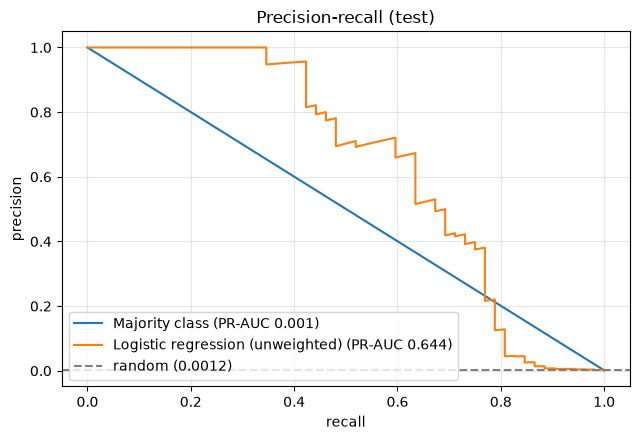

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, s in scores_te.items():
    p, r, _ = precision_recall_curve(yte, s)
    ax.plot(r, p, label=f"{name} (PR-AUC {results[name]['threshold_0.5']['pr_auc']:.3f})")
ax.axhline(prevalence, ls="--", c="grey", label=f"random ({prevalence:.4f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall (test)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "baseline_pr_curve.png"); plt.show()

**Analysis:** Logistic regression ranks fraud substantially better than the constant-score baseline: test PR-AUC is 0.644 versus a prevalence of about 0.0012. Precision and recall still trade off; the test curve is descriptive and should not be used to choose a threshold.

## 6. Confusion matrices for logistic regression (test)

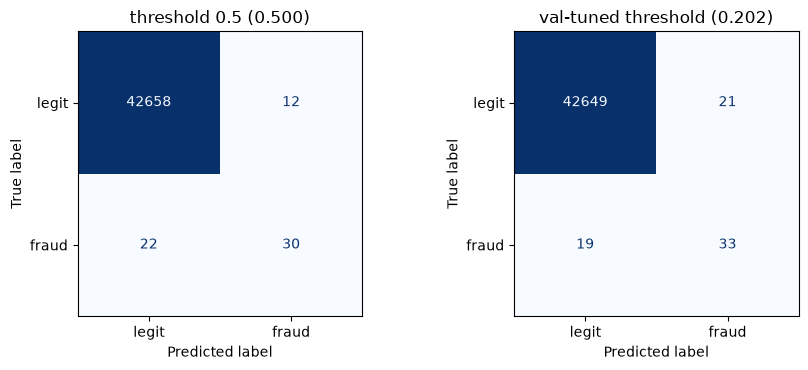

In [7]:
name = "Logistic regression (unweighted)"
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (label, key) in zip(axes, [("threshold 0.5", "threshold_0.5"), ("val-tuned threshold", "threshold_tuned_on_val")]):
    thr = results[name][key]["threshold"]
    ConfusionMatrixDisplay.from_predictions(yte, (scores_te[name] >= thr).astype(int), ax=ax,
                                            display_labels=["legit", "fraud"], colorbar=False, cmap="Blues")
    ax.set_title(f"{label} ({thr:.3f})"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG / "baseline_confusion.png"); plt.show()

**Analysis:** Lowering the threshold from 0.5 to the validation-selected 0.202 catches three more frauds (30 to 33) and misses three fewer (22 to 19), at the cost of nine additional false positives (12 to 21). A later cost-based threshold can weigh these errors explicitly.

## 7. Threshold sensitivity on validation

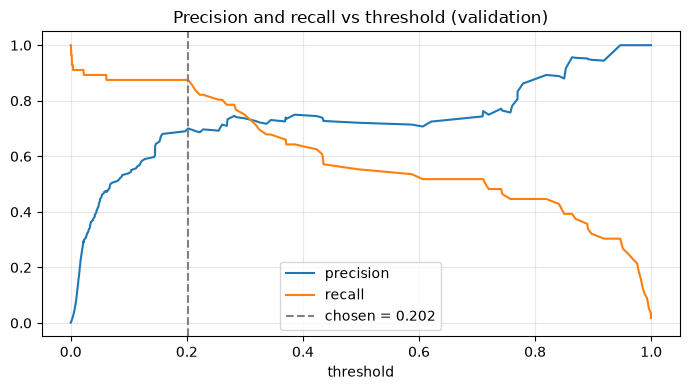

In [8]:
p, r, t = precision_recall_curve(yva, scores_va[name])
chosen = results[name]["threshold_tuned_on_val"]["threshold"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, p[:-1], label="precision"); ax.plot(t, r[:-1], label="recall")
ax.axvline(chosen, ls="--", c="grey", label=f"chosen = {chosen:.3f}")
ax.set_xlabel("threshold"); ax.set_title("Precision and recall vs threshold (validation)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "baseline_threshold.png"); plt.show()

**Analysis:** Validation F1 selects a threshold of approximately 0.202 using 56 frauds. The precision-recall tradeoff depends on that choice; the saved plot alone does not establish threshold stability. Assess stability on additional time-based validation windows before relying on this operating point.

## Takeaways and next step

| Observation | Leads to |
|---|---|
| At 0.5, 30 of 52 frauds are caught; at 0.202, 33 are caught with 9 more false alarms | Compare imbalance handling and validation-selected thresholds |
| PR-AUC is 0.644 and recall at 90% precision is 0.423 | Compare nonlinear models under the same temporal evaluation protocol |
| Test contains only 52 frauds | Report counts and assess robustness with time-based validation folds |

**Target for the boosted model:** exceed the logistic baseline PR-AUC of 0.644 and recall at 90% precision of 0.423, while reporting uncertainty and counts. Select models and thresholds on validation, not this test set.

**Next:** step 2 notebook (imbalance handling).